# Описание данных

Данные - специально подготовленная выборка из полного набора, описанного здесь: https://mengtingwan.github.io/data/goodreads#datasets с дополнениями из https://www.kaggle.com/datasets/austinreese/goodreads-books:
- books: перечень книг (~44 тыс.) из списка https://www.goodreads.com/list/show/1.Best_Books_Ever (совпадение по book id),
- interactions: взаимодействие пользователей с книгами

Основной массив данных был собран в конце 2017.

# Инициализация

In [85]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [86]:
%matplotlib inline
%config InlineBackend.figure_format = 'png'
%config InlineBackend.figure_format = 'retina'

Создаём логгер, который удобен для использования в ноутбуке.

# Load Data

Загружаем данные как они есть, начинаем на них смотреть: какие в них есть сущности, атрибуты, распределения.

In [88]:
books = pd.read_parquet("./books.parquet")

In [89]:
books.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43312 entries, 3 to 2360448
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   book_id               43312 non-null  int64  
 1   author                43312 non-null  object 
 2   title                 43312 non-null  object 
 3   description           43312 non-null  object 
 4   genre_and_votes       43312 non-null  object 
 5   num_pages             37001 non-null  Int64  
 6   average_rating        43312 non-null  float64
 7   ratings_count         43312 non-null  Int64  
 8   text_reviews_count    43312 non-null  int64  
 9   publisher             43312 non-null  object 
 10  publication_year      35891 non-null  Int64  
 11  country_code          43312 non-null  object 
 12  language_code         43312 non-null  object 
 13  format                43312 non-null  object 
 14  is_ebook              43312 non-null  bool   
 15  isbn                  

Пример данных по книгам

In [90]:
print(books[["book_id", "author", "title", "num_pages", "average_rating"]].sample(5, random_state=52).sort_values("book_id").set_index("book_id").to_string())

                                             author                                            title  num_pages  average_rating
book_id                                                                                                                        
69882                 Heinrich Böll, Patrick Bowles                      Billiards at Half-Past Nine        288            3.93
267533                               Robert Cormier                                         8 Plus 1        173            3.67
820966    Martin Luther, J.I. Packer, O.R. Johnston                          The Bondage of the Will        322            4.17
4532622                               Karen Hancock                                      The Enclave        492            3.82
20444381                             Diana Gabaldon  Os tambores de outono - 1ª Parte (Outlander #4)       1048            3.99


In [91]:
interactions = pd.read_parquet("./interactions.parquet")

Можно оценить объём данных о взаимодействиях

In [92]:
interactions.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12890434 entries, 0 to 12914458
Data columns (total 7 columns):
 #   Column       Dtype 
---  ------       ----- 
 0   user_id      object
 1   book_id      int64 
 2   started_at   object
 3   read_at      object
 4   is_read      bool  
 5   rating       int64 
 6   is_reviewed  bool  
dtypes: bool(2), int64(2), object(3)
memory usage: 614.7+ MB


Пример данных по взаимодействиям

In [93]:
print(interactions[["user_id", "book_id", "started_at", "read_at", "is_read", "rating"]].sample(5, random_state=52).sort_values("user_id").set_index(["user_id", "book_id"]).to_string())

                                           started_at     read_at  is_read  rating
user_id                          book_id                                          
0447747f44c0d8d1a08cf329fe253f29 10054335  2016-04-08  2016-04-20     True       3
14432756ffba6357686f09e4ccc332bb 26252859  2016-05-27  2016-05-30     True       5
46d6c8cf548d1c86abb671f42ba71b5e 960       2014-08-06  2016-10-29     True       5
71c2b3714945af1f700f49953904c510 18492859  2014-10-09  2014-10-12     True       5
7802bafdeac8abff23a72b9dd60b1dd1 18710190  2015-03-01  2015-05-05     True       4


# EDA

Посмотрим на данные о книгах, какие поля есть.

In [94]:
books.sample(3).T

,1929538,2301148,1708975
book_id,249043,162719,421736
author,William Golding,Margaret Peterson Haddix,"Stuart N. Lake, Doug Grad, Loren D. Estleman"
title,Darkness Visible,"Just Ella (The Palace Chronicles, #1)",Wyatt Earp: Frontier Marshal
description,A dazzlingly dark novel by the Nobel Laureate....,Being a princess isn't all that...\nYou've hea...,Wyatt Earp was the greatest gun-fighting marsh...
genre_and_votes,"{'Fiction': 49, 'Literature': 17, 'Literary Fi...","{'Fantasy': 785, 'Young Adult': 623, 'Fantasy-...","{'Biography': 15, 'History': 14, 'Nonfiction':..."
num_pages,272,240,416
average_rating,3.57,3.75,3.77
ratings_count,748,28095,194
text_reviews_count,52,1135,18
publisher,"Farrar, Straus and Giroux",Simon Pulse,Pocket Books


Посмотрим на данные о взаимодействиях пользователей с книгами.

In [95]:
books["book_id"].nunique()

43312

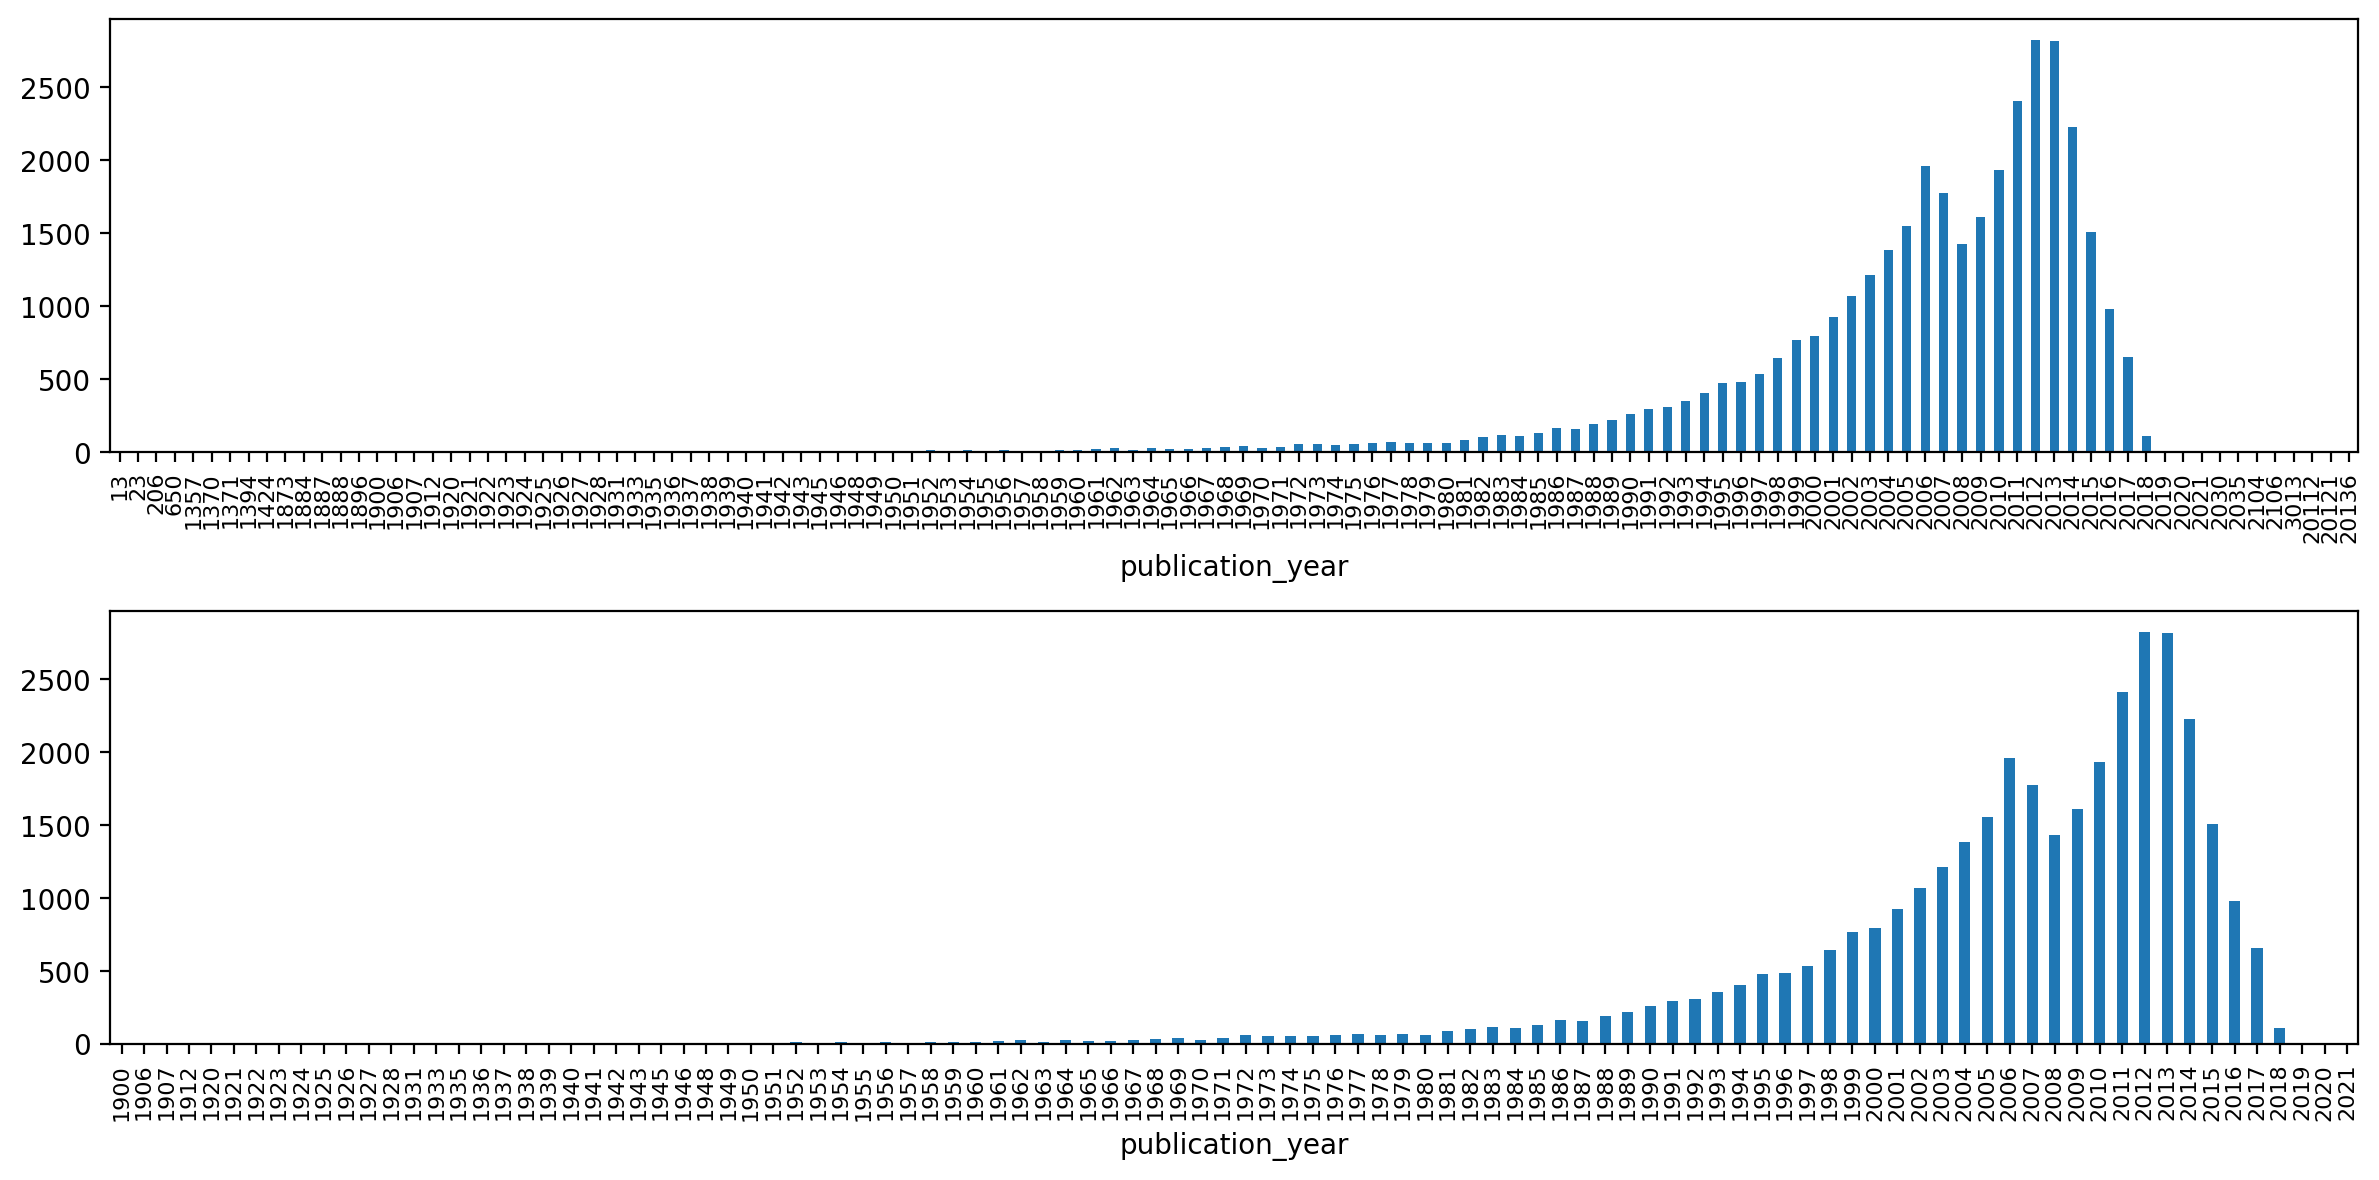

In [96]:
# распределение книг по годам публикации

fig, axs = plt.subplots(2, 1, figsize=(12, 6))

ax = axs[0]
books["publication_year"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.tick_params(axis='x', labelsize=8)

ax = axs[1]
books.query("publication_year >= 1900 and publication_year <= 2025")["publication_year"].value_counts().sort_index().plot(kind="bar", ax=ax)
ax.tick_params(axis='x', labelsize=8)

fig.tight_layout()

# События по месяцам

In [97]:
from pandas.tseries.offsets import MonthEnd

interactions["started_at_month"] = pd.to_datetime(interactions["started_at"]).dt.to_period('M').dt.to_timestamp().dt.date

In [98]:
interactions_by_month = interactions.groupby("started_at_month").agg(events=("started_at", "count"), users=("user_id", "nunique")).reset_index()

In [99]:
interactions_by_month

,started_at_month,events,users
0,2007-01-01,1993,1071
1,2007-02-01,201,135
2,2007-03-01,222,152
3,2007-04-01,201,135
4,2007-05-01,204,138
...,...,...,...
127,2017-08-01,202129,93040
128,2017-09-01,172187,82694
129,2017-10-01,108107,58076
130,2017-11-01,565,475


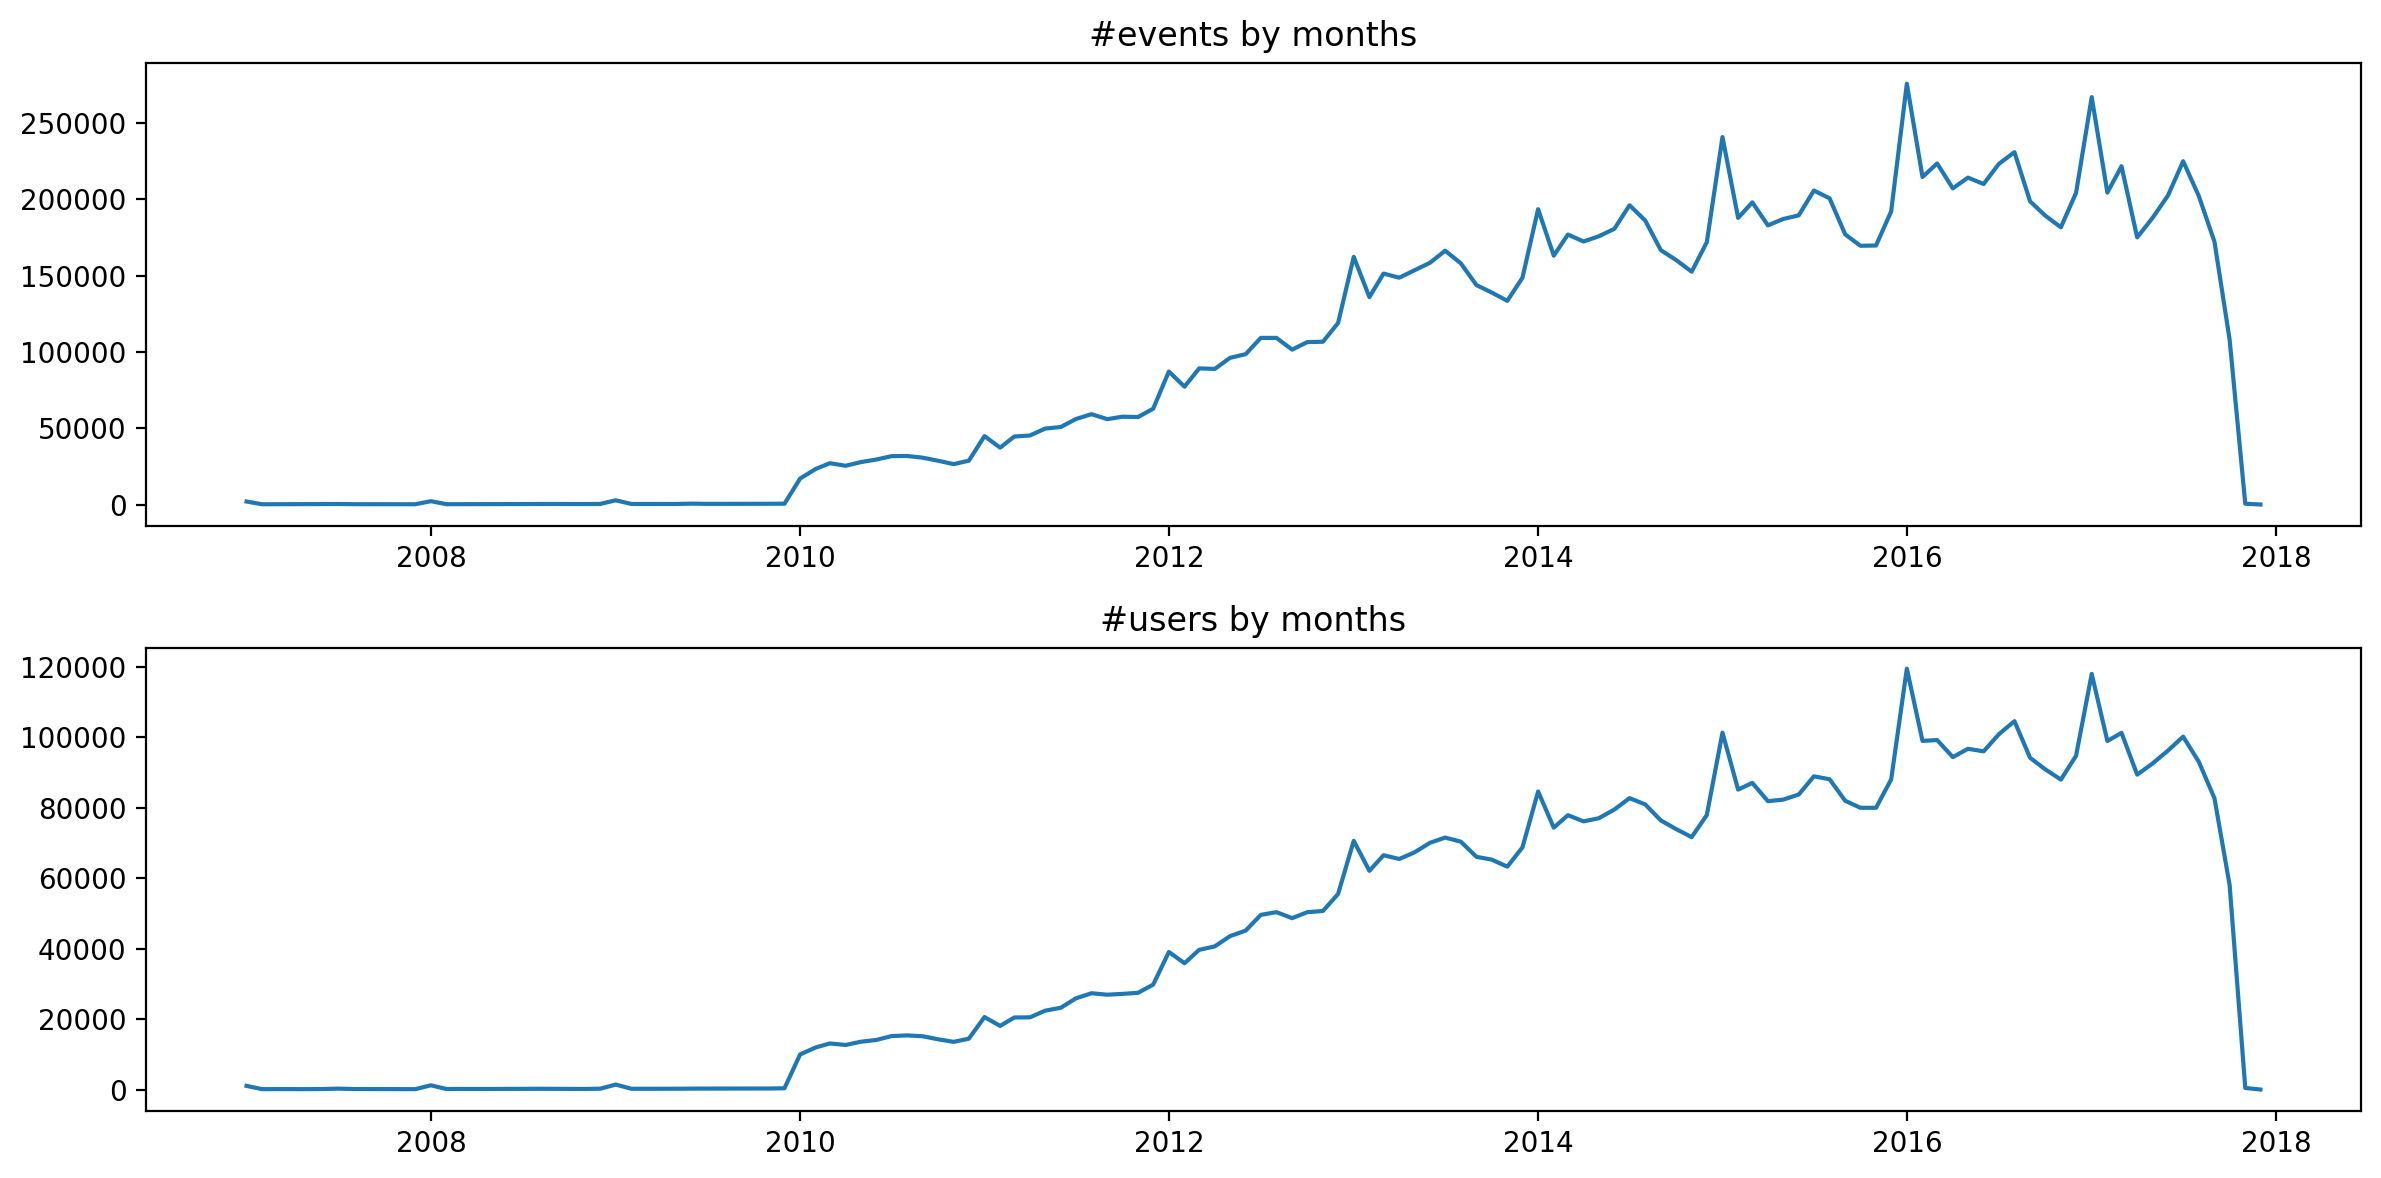

In [100]:
# распределение взаимодействий по годам

fig, axs = plt.subplots(2, 1, figsize=(12, 6))

ax = axs[0]
ax.plot(interactions_by_month["started_at_month"], interactions_by_month["events"])
# ax.tick_params(axis='x', labelsize=8)
ax.set_title("#events by months")

ax = axs[1]
ax.plot(interactions_by_month["started_at_month"], interactions_by_month["users"])
# ax.tick_params(axis='x', labelsize=8)
ax.set_title("#users by months")

fig.tight_layout()

# Преобработка

Примем новые именования:
- books -> items (более обобщённое название)
- interactions -> events (несколько короче, удобнее в коде)

In [101]:
items = books.copy()
events = interactions.copy()

In [102]:
del books
del interactions

In [103]:
# оставим события только до ноября 2017

event_cutoff_date = pd.to_datetime("2017-11-01").date()
events = events.query("started_at < @event_cutoff_date and read_at < @event_cutoff_date").copy()

In [104]:
events

,user_id,book_id,started_at,read_at,is_read,rating,is_reviewed,started_at_month
0,8842281e1d1347389f2ab93d60773d4d,22034,2015-07-12,2015-07-17,True,5,False,2015-07-01
1,8842281e1d1347389f2ab93d60773d4d,22318578,2015-06-07,2015-08-09,True,5,True,2015-06-01
2,8842281e1d1347389f2ab93d60773d4d,22551730,2015-06-24,2015-07-11,True,4,True,2015-06-01
3,8842281e1d1347389f2ab93d60773d4d,22816087,2015-09-27,2015-11-04,True,5,True,2015-09-01
4,8842281e1d1347389f2ab93d60773d4d,20527133,2015-05-05,2015-09-06,True,0,False,2015-05-01
...,...,...,...,...,...,...,...,...
12914454,d890e8079d8896e0cc6c4f178634850a,14836,2016-11-29,2017-01-15,True,3,False,2016-11-01
12914455,d0f6d1a4edcab80a6010cfcfeda4999f,14935,2012-06-10,2012-06-10,True,5,False,2012-06-01
12914456,b0883ebf8e31731f1c5d91e678c26666,10210,2012-06-05,2013-01-17,True,5,False,2012-06-01
12914457,b0883ebf8e31731f1c5d91e678c26666,99561,2012-07-21,2012-07-22,True,4,False,2012-07-01


In [105]:
# удалите события, для которых нет рейтинга
events = events.query('rating>0')

In [106]:
# оставьте события только c признаком is_read=True
events = events.query('is_read==True')

In [107]:
# оставьте только тех пользователей, у которых две прочитанные книги и более
readers2plus = list(events.groupby('user_id')['book_id'].nunique().reset_index().query('book_id>1')['user_id'].unique())
readers2plus[:10]

['00000377eea48021d3002730d56aca9a',
 '00004584d524ec468619e81b176cc991',
 '000079c580bbe45e1500acabe551b276',
 '00009e46d18f223a82b22da38586b605',
 '0000c3d51aa099745e93a4e99c4856c8',
 '0001085188e302fc6b2568de45a5f56b',
 '00014c578111090720e20f5705eba051',
 '000157a6f8331e9c9a21252e1fee91d1',
 '00017868aee19101bca0817fe915c881',
 '000192962b87d560f00b06fdcbd71681']

In [109]:
# отфильтровывваем id которые выбрали ранее
events = events.query('user_id.isin(@readers2plus)')

In [110]:
# Также переименуйте данные следующим образом (в пользу обобщённых названий):
# books — в items,
# interactions — в events.
# идентификатор book_id — в item_id, причём как в items, так и в events.
events = events.rename(columns={'books':'items',
                                'interactions':'events',
                                'book_id':'item_id'})

items = items.rename(columns={'book_id':'item_id'})

In [111]:
events

,user_id,item_id,started_at,read_at,is_read,rating,is_reviewed,started_at_month
0,8842281e1d1347389f2ab93d60773d4d,22034,2015-07-12,2015-07-17,True,5,False,2015-07-01
1,8842281e1d1347389f2ab93d60773d4d,22318578,2015-06-07,2015-08-09,True,5,True,2015-06-01
2,8842281e1d1347389f2ab93d60773d4d,22551730,2015-06-24,2015-07-11,True,4,True,2015-06-01
3,8842281e1d1347389f2ab93d60773d4d,22816087,2015-09-27,2015-11-04,True,5,True,2015-09-01
5,8842281e1d1347389f2ab93d60773d4d,17910054,2015-03-04,2015-07-28,True,3,False,2015-03-01
...,...,...,...,...,...,...,...,...
12914452,d890e8079d8896e0cc6c4f178634850a,5297,2017-02-07,2017-02-26,True,5,False,2017-02-01
12914453,d890e8079d8896e0cc6c4f178634850a,4900,2016-12-22,2016-12-29,True,2,False,2016-12-01
12914454,d890e8079d8896e0cc6c4f178634850a,14836,2016-11-29,2017-01-15,True,3,False,2016-11-01
12914456,b0883ebf8e31731f1c5d91e678c26666,10210,2012-06-05,2013-01-17,True,5,False,2012-06-01


In [112]:
items

,item_id,author,title,description,genre_and_votes,num_pages,average_rating,ratings_count,text_reviews_count,publisher,publication_year,country_code,language_code,format,is_ebook,isbn,isbn13,genre_and_votes_dict,genre_and_votes_str
3,6066819,Jennifer Weiner,Best Friends Forever,Addie Downs and Valerie Adler were eight when ...,"{'Womens Fiction-Chick Lit': 739, 'Fiction': 442}",368,3.49,51184,3282,Atria Books,2009,US,eng,Hardcover,False,0743294297,9780743294294,"{'Academic': None, 'Academic-Academia': None, ...","Womens Fiction-Chick Lit 739, Fiction 442"
6,378460,Michael Halberstam,The Wanting of Levine,,"{'Politics': 1, 'Humor': 1}",<NA>,4.38,12,4,Berkley Publishing Group,1979,US,,Paperback,False,0425040887,9780425040881,"{'Academic': None, 'Academic-Academia': None, ...","Politics 1user, Humor 1user"
15,89375,"Don Piper, Cecil Murphey",90 Minutes in Heaven: A True Story of Death an...,As he is driving home from a minister's confer...,"{'Christian': 395, 'Nonfiction': 392, 'Religio...",<NA>,3.91,68157,2885,,<NA>,US,,,False,0800759494,9780800759490,"{'Academic': None, 'Academic-Academia': None, ...","Christian 395, Nonfiction 392, Religion 142, S..."
16,89376,Randy Alcorn,Heaven,What is Heaven really going to be like? What w...,"{'Christian': 225, 'Religion-Theology': 154, '...",533,4.26,7345,566,,<NA>,US,eng,,False,0842379428,9780842379427,"{'Academic': None, 'Academic-Academia': None, ...","Christian 225, Religion-Theology 154, Nonficti..."
17,89377,Jennifer L. Holm,Penny from Heaven,It's 1953 and 11-year-old Penny dreams of a su...,"{'Historical-Historical Fiction': 284, 'Childr...",288,3.98,6949,615,Random House Books for Young Readers,2006,US,,Hardcover,False,037583687X,9780375836879,"{'Academic': None, 'Academic-Academia': None, ...","Historical-Historical Fiction 284, Childrens-M..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2360257,279660,James Goldman,The Lion in Winter,Insecure siblings fighting for their parents' ...,"{'Plays': 294, 'Historical-Historical Fiction'...",103,4.22,8227,100,Random House,2004,US,eng,Paperback,False,0812973356,9780812973358,"{'Academic': None, 'Academic-Academia': None, ...","Plays 294, Historical-Historical Fiction 110, ..."
2360258,7657484,"J. Michael Straczynski, Shane Davis, Sandra Ho...","Superman: Earth One, Volume 1",Forget everything you know about The Man of St...,"{'Sequential Art-Comics': 683, 'Sequential Art...",134,3.90,13221,578,DC Comics,2010,US,eng,Hardcover,False,1401224687,9781401224684,"{'Academic': None, 'Academic-Academia': None, ...","Sequential Art-Comics 683, Sequential Art-Grap..."
2360322,7715664,Larissa Ione,Sin Undone (Demonica #5),HER TOUCH IS DEADLY\nAs the only female Seminu...,"{'Romance-Paranormal Romance': 703, 'Fantasy-P...",400,4.35,23091,819,Grand Central Publishing,2010,US,eng,Mass Market Paperback,False,0446556815,9780446556811,"{'Academic': None, 'Academic-Academia': None, ...","Romance-Paranormal Romance 703, Fantasy-Parano..."
2360395,30367813,J.A. Owenby,The Truth She Knew (The Truth Series #1),"""A bittersweet story of young love, independen...","{'Fiction': 4, 'Romance': 3, 'Business-Amazon'...",238,4.34,111,67,,2016,US,eng,Paperback,False,1533660549,9781533660541,"{'Academic': None, 'Academic-Academia': None, ...","Fiction 4, Romance 3, Business-Amazon 3"


In [113]:
# Все оставшиеся после обработки данных идентификаторы нужно отсортировать
events = events.sort_values(by='user_id',ascending=True)

In [114]:
# и перекодируйте идентификаторы пользователей
user_ids = list(events['user_id'].unique())
start_id = 1000000
id_mapping = {old_id: new_id for new_id, old_id in enumerate(user_ids, start=start_id)}
events['uuid'] = events['user_id'].map(id_mapping)

In [115]:
events

,user_id,item_id,started_at,read_at,is_read,rating,is_reviewed,started_at_month,uuid
6679625,00000377eea48021d3002730d56aca9a,11012,2015-12-05,2015-12-11,True,4,False,2015-12-01,1000000
6679617,00000377eea48021d3002730d56aca9a,4671,2014-06-05,2014-06-30,True,5,False,2014-06-01,1000000
6679618,00000377eea48021d3002730d56aca9a,5,2012-10-02,2012-10-24,True,5,False,2012-10-01,1000000
6679620,00000377eea48021d3002730d56aca9a,2,2009-07-12,2009-07-29,True,5,False,2009-07-01,1000000
6679621,00000377eea48021d3002730d56aca9a,14497,2016-05-09,2016-06-02,True,5,False,2016-05-01,1000000
...,...,...,...,...,...,...,...,...,...
5625379,fffff8a718843c0e11dfd93fb41c1297,25111004,2016-12-08,2016-12-08,True,5,False,2016-12-01,1430584
5625378,fffff8a718843c0e11dfd93fb41c1297,6606855,2017-03-01,2017-03-01,True,3,False,2017-03-01,1430584
5625377,fffff8a718843c0e11dfd93fb41c1297,18812405,2017-05-05,2017-05-31,True,3,True,2017-05-01,1430584
5625376,fffff8a718843c0e11dfd93fb41c1297,18692431,2017-08-02,2017-08-09,True,3,True,2017-08-01,1430584


# Ваш код здесь

In [116]:
# Количество уникальных пользователей
num_users = events['user_id'].nunique()
print(f"Количество пользователей: {num_users}")

Количество пользователей: 430585


In [118]:
# Среднее количество прочитанных книг на пользователя
avg_books_per_user = events.groupby('user_id')['item_id'].nunique().mean()
print(f"Среднее количество прочитанных книг на пользователя: {avg_books_per_user:.2f}")

Среднее количество прочитанных книг на пользователя: 27.29


In [119]:
# Доля прочитанных книг, у которых нет рейтинга
if 'rating' in events.columns:
    no_rating_share = events['rating'].isna().mean()
    print(f"Доля книг без рейтинга: {no_rating_share:.2%}")
else:
    print("Колонка 'rating' отсутствует в данных.")

Доля книг без рейтинга: 0.00%


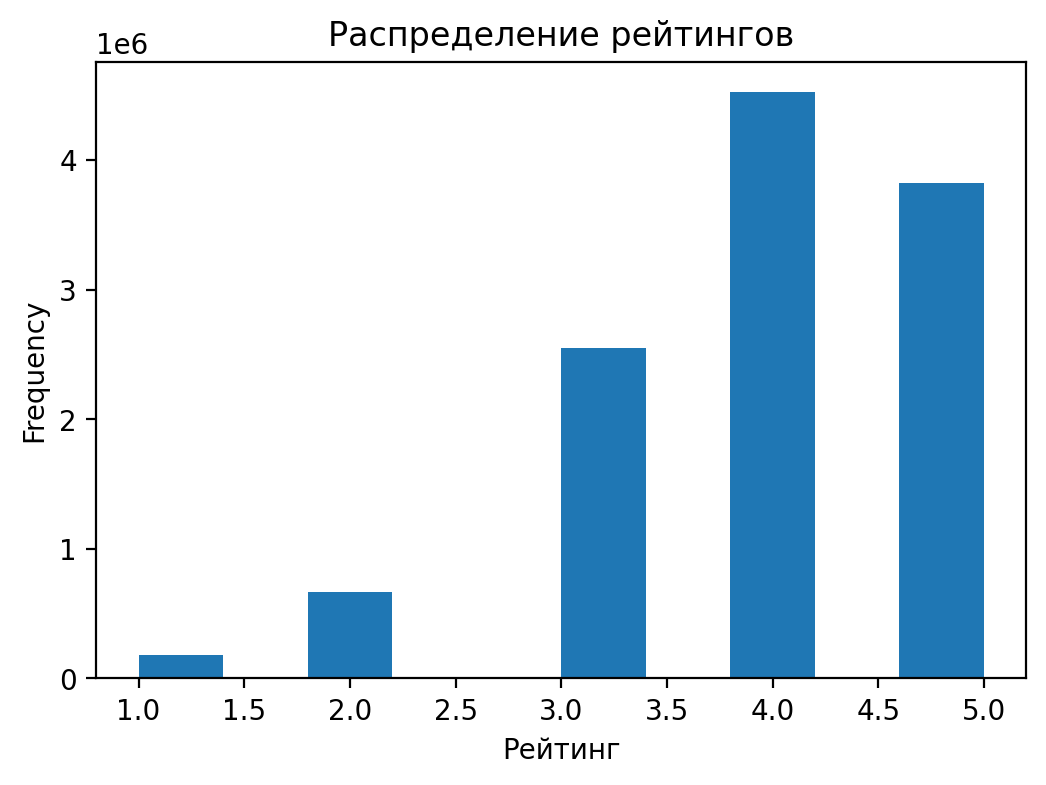

In [120]:
# Распределение рейтингов
if 'rating' in events.columns:
    plt.figure(figsize=(6,4))
    events['rating'].dropna().plot(kind='hist', bins=10, title='Распределение рейтингов')
    plt.xlabel('Рейтинг')
    plt.show()

In [121]:
events

,user_id,item_id,started_at,read_at,is_read,rating,is_reviewed,started_at_month,uuid
6679625,00000377eea48021d3002730d56aca9a,11012,2015-12-05,2015-12-11,True,4,False,2015-12-01,1000000
6679617,00000377eea48021d3002730d56aca9a,4671,2014-06-05,2014-06-30,True,5,False,2014-06-01,1000000
6679618,00000377eea48021d3002730d56aca9a,5,2012-10-02,2012-10-24,True,5,False,2012-10-01,1000000
6679620,00000377eea48021d3002730d56aca9a,2,2009-07-12,2009-07-29,True,5,False,2009-07-01,1000000
6679621,00000377eea48021d3002730d56aca9a,14497,2016-05-09,2016-06-02,True,5,False,2016-05-01,1000000
...,...,...,...,...,...,...,...,...,...
5625379,fffff8a718843c0e11dfd93fb41c1297,25111004,2016-12-08,2016-12-08,True,5,False,2016-12-01,1430584
5625378,fffff8a718843c0e11dfd93fb41c1297,6606855,2017-03-01,2017-03-01,True,3,False,2017-03-01,1430584
5625377,fffff8a718843c0e11dfd93fb41c1297,18812405,2017-05-05,2017-05-31,True,3,True,2017-05-01,1430584
5625376,fffff8a718843c0e11dfd93fb41c1297,18692431,2017-08-02,2017-08-09,True,3,True,2017-08-01,1430584


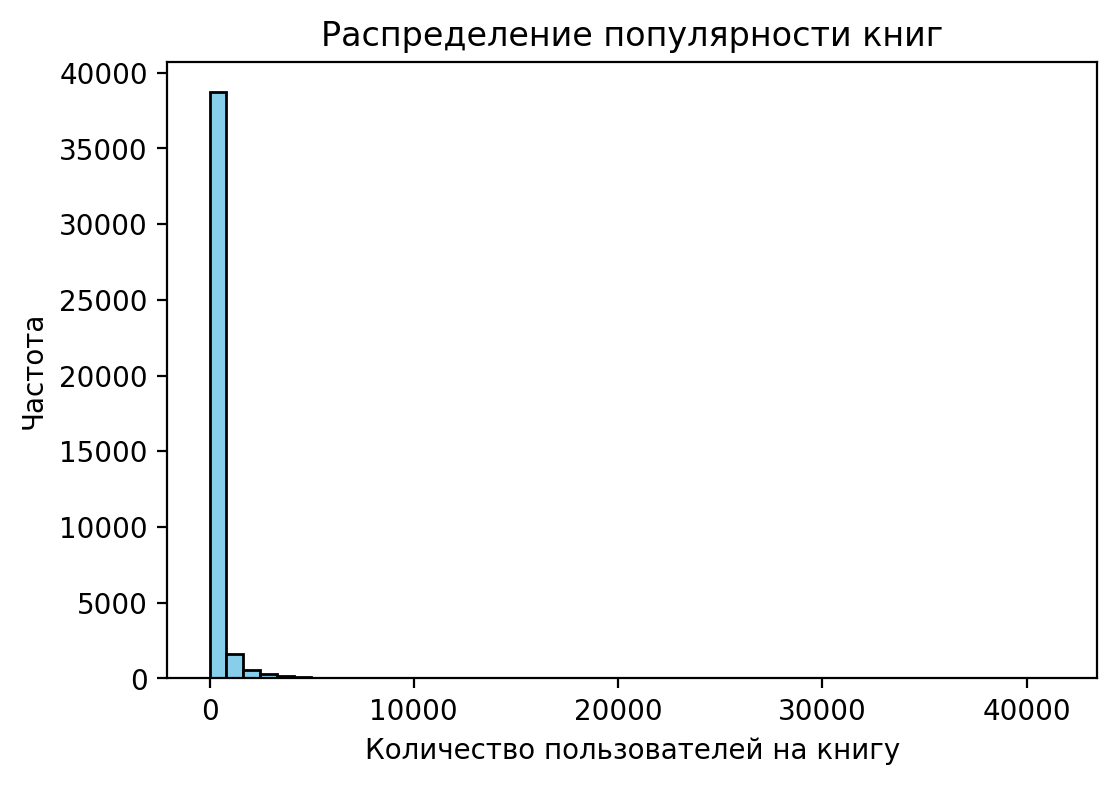

In [123]:
# Распределение популярности книг (сколько пользователей прочитало каждую книгу)
popularity = events.groupby('item_id')['user_id'].nunique()
plt.figure(figsize=(6,4))
plt.hist(popularity, bins=50, color='skyblue', edgecolor='black')
plt.title('Распределение популярности книг')
plt.xlabel('Количество пользователей на книгу')
plt.ylabel('Частота')
plt.show()

In [124]:
# Распределение количества взаимодействий по времени (если есть колонка времени)
time_col = None
for col in events.columns:
    if 'time' in col or 'date' in col:
        time_col = col
        break

if time_col:
    events[time_col] = pd.to_datetime(events[time_col], errors='coerce')
    events[time_col].dt.to_period('M').value_counts().sort_index().plot(kind='bar', figsize=(10,4))
    plt.title('Распределение количества взаимодействий по месяцам')
    plt.ylabel('Количество взаимодействий')
    plt.show()
else:
    print("Колонка с временем взаимодействий не найдена.")

Колонка с временем взаимодействий не найдена.


In [126]:
# Проверка логических нестыковок и странностей
print("\n--- Проверка на логические нестыковки ---")
if 'rating' in events.columns:
    negative_ratings = events[events['rating'] < 0]
    high_ratings = events[events['rating'] > 10]
    if not negative_ratings.empty or not high_ratings.empty:
        print("Найдены некорректные значения рейтингов (меньше 0 или больше 10)")
    else:
        print("Рейтинги в норме (0-10).")

duplicates = events.duplicated(subset=['user_id', 'item_id'], keep=False)
if duplicates.any():
    print(f"Найдены дубликаты взаимодействий: {duplicates.sum()} строк(и)")
else:
    print("Дубликатов взаимодействий не найдено.")

print("Проверка завершена.")


--- Проверка на логические нестыковки ---
Рейтинги в норме (0-10).
Дубликатов взаимодействий не найдено.
Проверка завершена.


# Сохранение результатов

In [127]:
items.to_parquet("items.par")

In [128]:
events.to_parquet("events.par")

In [130]:
# Какая доля событий осталась после обработки данных?
11751086 /12914458

0.9099170867255908

In [131]:
# Какой новый идентификатор у пользователя с изначальным идентификатором 8f50136afeb65c55cec7b3d306c24b03?
events.query('user_id=="8f50136afeb65c55cec7b3d306c24b03"')

,user_id,item_id,started_at,read_at,is_read,rating,is_reviewed,started_at_month,uuid
10841363,8f50136afeb65c55cec7b3d306c24b03,253058,2012-12-29,2013-01-22,True,3,True,2012-12-01,1241243
10841364,8f50136afeb65c55cec7b3d306c24b03,10572,2012-01-02,2013-01-27,True,5,False,2012-01-01,1241243


In [132]:
# зададим точку разбиения
train_test_global_time_split_date = pd.to_datetime("2017-08-01").date()

train_test_global_time_split_idx = events["started_at"] < train_test_global_time_split_date
events_train = events[train_test_global_time_split_idx]
events_test = events[~train_test_global_time_split_idx]

# количество пользователей в train и test
users_train = events_train["user_id"].drop_duplicates()
users_test = events_test["user_id"].drop_duplicates()
# количество пользователей, которые есть и в train, и в test
common_users = set(users_train).intersection(set(users_test))

print(len(users_train), len(users_test), len(common_users))

428220 123223 120858


In [133]:
# холодные пользователи — это те, которые есть в тестовой выборке, но отсутствуют в обучающей
cold_users = set(users_test) - set(users_train)

print(len(cold_users))

2365


In [134]:
# Завершите код, чтобы получить топ-100 наиболее популярных книг согласно условиям выше.
from sklearn.preprocessing import MinMaxScaler

top_pop_start_date = pd.to_datetime("2015-01-01").date()

item_popularity = events_train \
    .query("started_at >= @top_pop_start_date") \
    .groupby(["item_id"]).agg(users=("user_id", "nunique"), avg_rating=("rating", "mean")).reset_index()

# нормализация пользователей и среднего рейтинга, требуется для их приведения к одному масштабу
scaler = MinMaxScaler()
item_popularity[["users_norm", "avg_rating_norm"]] = scaler.fit_transform(
    item_popularity[["users", "avg_rating"]]
)

# вычисляем popularity_score, как скор популярности со штрафом за низкий рейтинг
item_popularity["popularity_score"] = (
    item_popularity["users_norm"] * item_popularity["avg_rating_norm"]
)

# сортируем по убыванию popularity_score
item_popularity = item_popularity.sort_values("popularity_score", ascending=False)

# выбираем первые 100 айтемов со средней оценкой avg_rating не меньше 4
top_k_pop_items = item_popularity[item_popularity["avg_rating"] >= 4].head(100)

In [137]:
top_k_pop_items.iloc[0]["users"]

20207.0

In [138]:
# добавляем информацию о книгах
top_k_pop_items = top_k_pop_items.merge(
    items.set_index("item_id")[["author", "title", "genre_and_votes", "publication_year"]], on="item_id")

with pd.option_context('display.max_rows', 100):
    display(top_k_pop_items[["item_id", "author", "title", "publication_year", "users", "avg_rating", "popularity_score", "genre_and_votes"]])

,item_id,author,title,publication_year,users,avg_rating,popularity_score,genre_and_votes
0,18007564,Andy Weir,The Martian,2014,20207,4.321275,0.412333,"{'Science Fiction': 11966, 'Fiction': 8430}"
1,18143977,Anthony Doerr,All the Light We Cannot See,2014,19462,4.290669,0.393471,"{'Historical-Historical Fiction': 13679, 'Fict..."
2,3,"J.K. Rowling, Mary GrandPré",Harry Potter and the Sorcerer's Stone (Harry P...,1997,15139,4.706057,0.344702,"{'Fantasy': 59818, 'Fiction': 17918, 'Young Ad..."
3,16096824,Sarah J. Maas,A Court of Thorns and Roses (A Court of Thorns...,2015,16770,4.301014,0.340108,"{'Fantasy': 14326, 'Young Adult': 4662, 'Roman..."
4,15881,"J.K. Rowling, Mary GrandPré",Harry Potter and the Chamber of Secrets (Harry...,1999,13043,4.632447,0.291076,"{'Fantasy': 50130, 'Young Adult': 15202, 'Fict..."
5,38447,Margaret Atwood,The Handmaid's Tale,1998,14611,4.232770,0.290194,"{'Fiction': 15424, 'Classics': 9937, 'Science ..."
6,11235712,Marissa Meyer,"Cinder (The Lunar Chronicles, #1)",2012,14348,4.179189,0.280247,"{'Young Adult': 10539, 'Fantasy': 9237, 'Scien..."
7,17927395,Sarah J. Maas,A Court of Mist and Fury (A Court of Thorns an...,2016,12177,4.730640,0.279094,"{'Fantasy': 10186, 'Romance': 3346, 'Young Adu..."
8,5,"J.K. Rowling, Mary GrandPré",Harry Potter and the Prisoner of Azkaban (Harr...,2004,11890,4.770143,0.275401,"{'Fantasy': 49784, 'Young Adult': 15393, 'Fict..."
9,13206900,Marissa Meyer,"Winter (The Lunar Chronicles, #4)",2015,12291,4.534293,0.266881,"{'Fantasy': 4835, 'Young Adult': 4672, 'Scienc..."


In [141]:
# Завершите предлагаемый код, чтобы в cold_users_events_with_recs для каждого события получить столбец avg_rating. В нём при совпадении по item_id будет значение из одноимённого столбца из top_k_pop_items, иначе — пропуск.
# В cold_users_events_with_recs после выполнения завершённого кода должно быть столько же строк, сколько было до его выполнения.
cold_users_events_with_recs = \
    events_test[events_test["user_id"].isin(cold_users)] \
    .merge(top_k_pop_items.reset_index()[["item_id", "avg_rating"]],  # вернуть item_id из индекса
           on="item_id", how="left")

cold_user_items_no_avg_rating_idx = cold_users_events_with_recs["avg_rating"].isnull()
cold_user_recs = cold_users_events_with_recs[~cold_user_items_no_avg_rating_idx] \
    [["user_id", "item_id", "rating", "avg_rating"]]

In [146]:
# доля событий холодных пользователей, где найдена рекомендация (совпадение по item_id)
share_recommended = (
    cold_users_events_with_recs["avg_rating"].notna().mean()
)

print(round(share_recommended, 2))

0.2


In [147]:
# Посчитайте метрики rmse и mae для полученных рекомендаций.
# посчитаем метрики рекомендаций
from sklearn.metrics import mean_squared_error, mean_absolute_error

rmse = mean_squared_error(cold_user_recs["rating"], cold_user_recs["avg_rating"], squared=False)
mae = mean_absolute_error(cold_user_recs["rating"], cold_user_recs["avg_rating"])
print(round(rmse, 2), round(mae, 2))

0.78 0.62


In [148]:
# посчитаем покрытие холодных пользователей рекомендациями

cold_users_hit_ratio = cold_users_events_with_recs.groupby("user_id").agg(hits=("avg_rating", lambda x: (~x.isnull()).mean()))

print(f"Доля пользователей без релевантных рекомендаций: {(cold_users_hit_ratio == 0).mean().iat[0]:.2f}")
print(f"Среднее покрытие пользователей: {cold_users_hit_ratio[cold_users_hit_ratio != 0].mean().iat[0]:.2f}")

Доля пользователей без релевантных рекомендаций: 0.59
Среднее покрытие пользователей: 0.44


In [149]:
# считаем количество пользователей, книг и событий
n_users = events["user_id"].nunique()
n_items = events["item_id"].nunique()
n_events = len(events)

# считаем разреженность
sparsity = 1 - (n_events / (n_users * n_items))
print(f"Разреженность матрицы: {sparsity:.4f}")


Разреженность матрицы: 0.9993


In [157]:
from surprise import Dataset, Reader
from surprise import SVD

# используем Reader из библиотеки surprise для преобразования событий (events)
# в формат, необходимый surprise
reader = Reader(rating_scale=(1, 5))
surprise_train_set = Dataset.load_from_df(events_train[['user_id', 'item_id', 'rating']], reader)
surprise_train_set = surprise_train_set.build_full_trainset()

# инициализируем модель
svd_model = SVD(n_factors=100, random_state=0)

# обучаем модель
svd_model.fit(surprise_train_set)

In [158]:
# Используя обученную модель, получим рекомендации для тестовой выборки:
surprise_test_set = list(events_test[['user_id', 'item_id', 'rating']].itertuples(index=False))

# получаем рекомендации для тестовой выборки
svd_predictions = svd_model.test(surprise_test_set)

In [159]:
# Оценка рекомендаций
# Полученные рекомендации можно оценить, используя встроенный модуль accuracy из библиотеки surprise:
from surprise import accuracy

rmse = accuracy.rmse(svd_predictions)
mae = accuracy.mae(svd_predictions)
                     
print(rmse, mae)

RMSE: 0.8263
MAE:  0.6460
0.826346375350908 0.6460143973270805


In [160]:
from surprise import NormalPredictor

# инициализируем состояние генератора, это необходимо для получения
# одной и той же последовательности случайных чисел, только в учебных целях
np.random.seed(0)

random_model = NormalPredictor()

random_model.fit(surprise_train_set)
random_predictions = random_model.test(surprise_test_set)

In [162]:
# Рассчитайте значение MAE для random_predictions.
# На сколько процентов MAE для случайных рекомендаций от NormalPredictor выше значения MAE от SVD? Ответ округлите до целых.
# фиксируем seed для воспроизводимости
np.random.seed(0)

# создаём и обучаем случайную модель
random_model = NormalPredictor()
random_model.fit(surprise_train_set)

# делаем предсказания
random_predictions = random_model.test(surprise_test_set)

# считаем MAE для случайных рекомендаций (ОБЯЗАТЕЛЬНО эта строка!)
mae_random = accuracy.mae(random_predictions, verbose=False)

# считаем, на сколько процентов MAE у SVD меньше, чем у случайных
improvement_percent = (1 - (mae / mae_random)) * 100

print(f"MAE случайных рекомендаций: {mae_random:.2f}")
print(f"MAE модели SVD: {mae:.2f}")
print(f"SVD лучше случайных на {round(improvement_percent)}%")

MAE случайных рекомендаций: 1.00
MAE модели SVD: 0.65
SVD лучше случайных на 35%


In [167]:
# Создайте функцию, которая позволит получить рекомендации для конкретного пользователя, используя описанный подход. Дополните прекод.
def get_recommendations_svd(user_id, all_items, events, model, include_seen=True, n=5):

    """ возвращает n рекомендаций для user_id """
    
    # получим список идентификаторов всех книг
    all_items = set(events['item_id'].unique())
        
    # учитываем флаг, стоит ли уже прочитанные книги включать в рекомендации
    if include_seen:
        items_to_predict = list(all_items)
    else:
        # получим список книг, которые пользователь уже прочитал ("видел")
        seen_items = set(events[events["user_id"] == user_id]['item_id'].unique())
        
        # книги, которые пользователь ещё не читал
        # только их и будем включать в рекомендации
        items_to_predict = list(all_items - seen_items)
    
    # получаем скоры для списка книг, т. е. рекомендации
    predictions = [model.predict(user_id, item_id) for item_id in items_to_predict]
    
    # сортируем рекомендации по убыванию скора и берём только n первых
    recommendations = sorted(predictions, key=lambda x: x.est, reverse=True)[:n]
    
    return pd.DataFrame([(pred.iid, pred.est) for pred in recommendations], columns=["item_id", "score"])

In [168]:
# Какое значение item_id третьей рекомендации (по убыванию score) для пользователя 1296647? Получить рекомендации для данного пользователя можно вызовом функции get_recommendations_svd:
get_recommendations_svd(1296647, items, events_test, svd_model)

,item_id,score
0,22037424,4.925429
1,11221285,4.898793
2,33353628,4.894097
3,29844341,4.852367
4,481749,4.829741


In [169]:
# выберем произвольного пользователя из тренировочной выборки ("прошлого")
user_id = events_train['user_id'].sample().iat[0]

print(f"user_id: {user_id}")

print("История (последние события, recent)")
user_history = (
    events_train
    .query("user_id == @user_id")
    .merge(items.set_index("item_id")[["author", "title", "genre_and_votes"]], on="item_id")
)
user_history_to_print = user_history[["author", "title", "started_at", "read_at", "rating", "genre_and_votes"]].tail(10)
display(user_history_to_print)

print("Рекомендации")
user_recommendations = get_recommendations_svd(user_id, items, events_train, svd_model)
user_recommendations = user_recommendations.merge(items[["item_id", "author", "title", "genre_and_votes"]], on="item_id")
display(user_recommendations)

user_id: 415d108afffbba9c2b2599430da64b49
История (последние события, recent)


,author,title,started_at,read_at,rating,genre_and_votes
0,Patrick Rothfuss,"The Wise Man's Fear (The Kingkiller Chronicle,...",2015-06-17,2015-08-31,5,"{'Fantasy': 16491, 'Fiction': 2222, 'Fantasy-E..."
1,Andy Weir,The Martian,2014-12-07,2014-12-11,4,"{'Science Fiction': 11966, 'Fiction': 8430}"
2,Brandon Sanderson,"The Way of Kings (The Stormlight Archive, #1)",2015-08-31,2015-10-30,5,"{'Fantasy': 14291, 'Fiction': 1623, 'Fantasy-E..."
3,Brandon Sanderson,"Words of Radiance (The Stormlight Archive, #2)",2015-10-30,2016-03-17,5,"{'Fantasy': 8542, 'Fiction': 872, 'Fantasy-Epi..."
4,Ken Follett,"Fall of Giants (The Century Trilogy, #1)",2016-05-12,2016-08-30,4,"{'Historical-Historical Fiction': 4665, 'Ficti..."


Рекомендации


,item_id,score,author,title,genre_and_votes
0,30688013,5.000000,Robin Hobb,"Assassin's Fate (The Fitz and the Fool, #3)","{'Fantasy': 1657, 'Fiction': 172, 'Fantasy-Epi..."
1,11221285,5.000000,Brandon Sanderson,"The Way of Kings, Part 2 (The Stormlight Archi...","{'Fantasy': 641, 'Fiction': 46, 'Fantasy-Epic ..."
2,19219646,5.000000,Wolfgang Herrndorf,Arbeit und Struktur,"{'Nonfiction': 25, 'European Literature-German..."
3,22037424,4.996202,"J.K. Rowling, Jonny Duddle, Tomislav Tomić",Harry Potter and the Prisoner of Azkaban (Harr...,"{'Fantasy': 49994, 'Young Adult': 15433, 'Fict..."
4,2168850,4.995777,"محمد بن إدريس الشافعي, إميل بديع يعقوب",ديوان الإمام الشافعي,"{'Poetry': 93, 'Religion': 15, 'Literature': 1..."
